# 🌍 Peak-GCN — Multi-Species Graph Convolutional Classifier
## Supervised Species Classification from Seismic Footstep Graphs (GCN version)

**Strategy:** Unlike the earlier one-class Elephant-only Autoencoder, this notebook trains on
**ALL species / all classes** in the dataset, using their real labels, so the model learns to
tell species apart. Given a brand-new signal, the trained model outputs a predicted species
(with a confidence score).

**How it works:**
- **Graph extraction:** identical to the earlier notebook — footstep impact peaks become nodes
  (8-D features), connected by a temporal chain + k-NN similarity edges.
- **Encoder (GCN):** 2-layer `GCNConv`, same as before, producing node embeddings.
- **Pooling:** `global_mean_pool` turns the variable-size set of node embeddings into one
  fixed-size graph embedding (this was missing before, since the old model only needed
  node-level reconstruction).
- **Classifier head:** a small MLP maps the graph embedding to `num_classes` logits.
- **Loss:** `CrossEntropyLoss` on the real species label (not MSE reconstruction).

**Dataset:** `dset_allspec_150_chunks_clean.nc` — **all classes kept**, no filtering.


---
## 🔧 STEP 1: Setup & GPU Configuration
**What I'm doing:** Importing PyTorch, checking CUDA/GPU availability, auto-selecting the GPU
with the most free VRAM, and fixing random seeds for reproducibility.


In [1]:
import torch, os, numpy as np
print(f'PyTorch version : {torch.__version__}')
print(f'CUDA available  : {torch.cuda.is_available()}')

if torch.cuda.is_available():
    num_gpus = torch.cuda.device_count()
    print(f'GPU count       : {num_gpus}')
    best_gpu_idx = 0
    max_free_mem = 0
    print('\nChecking VRAM availability across all GPUs:')
    for i in range(num_gpus):
        try:
            free_mem, total_mem = torch.cuda.mem_get_info(i)
            free_gb  = free_mem  / (1024**3)
            total_gb = total_mem / (1024**3)
            print(f'  GPU {i}: {torch.cuda.get_device_name(i):22s} | Free: {free_gb:5.1f} GB / {total_gb:5.1f} GB')
            if free_mem > max_free_mem:
                max_free_mem = free_mem
                best_gpu_idx = i
        except Exception as e:
            print(f'  GPU {i}: Could not query memory ({e})')
    device = torch.device(f'cuda:{best_gpu_idx}')
    torch.cuda.set_device(device)
    torch.cuda.empty_cache()
    print(f'\n🚀 Automatically selected GPU {best_gpu_idx} ({torch.cuda.get_device_name(best_gpu_idx)}) with {max_free_mem/(1024**3):.1f} GB free VRAM!')
else:
    device = torch.device('cpu')
    print('Using device    : cpu')

SEED = 42; torch.manual_seed(SEED); np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print('Setup complete ✓')


PyTorch version : 2.8.0+cu128
CUDA available  : True
GPU count       : 8

Checking VRAM availability across all GPUs:
  GPU 0: NVIDIA A100-SXM4-80GB  | Free:  20.7 GB /  79.2 GB
  GPU 1: NVIDIA A100-SXM4-80GB  | Free:  39.1 GB /  79.2 GB
  GPU 2: NVIDIA A100-SXM4-80GB  | Free:  68.4 GB /  79.2 GB
  GPU 3: NVIDIA A100-SXM4-80GB  | Free:  68.4 GB /  79.2 GB
  GPU 4: NVIDIA A100-SXM4-80GB  | Free:  62.8 GB /  79.2 GB
  GPU 5: NVIDIA A100-SXM4-80GB  | Free:  68.0 GB /  79.2 GB
  GPU 6: NVIDIA A100-SXM4-80GB  | Free:  61.9 GB /  79.2 GB
  GPU 7: NVIDIA A100-SXM4-80GB  | Free:  24.2 GB /  79.2 GB

🚀 Automatically selected GPU 2 (NVIDIA A100-SXM4-80GB) with 68.4 GB free VRAM!
Setup complete ✓


---
## 📂 STEP 2: Load Dataset & Inspect Class Distribution
**What I'm doing:** Opening the NetCDF dataset and listing how many recordings exist per class.
Unlike the Elephant-only notebook, **we do NOT filter down to a single class** — every species
stays in the dataset because the model now needs to learn to tell them apart.

Edit `CLASS_NAMES` below to match your actual species labels (only Class 1 = Elephant is known
from the earlier notebook; fill in the rest, or leave the defaults as `Class {id}`).


In [2]:
import netCDF4 as nc

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'
dataset = nc.Dataset(FILE_PATH, mode='r')
print('Variable Shapes:')
for v in dataset.variables.keys():
    print(f'  {v:12s}: {dataset.variables[v].shape}')

all_labels_raw = dataset['class'][:].astype(int)
unique_classes, class_counts = np.unique(all_labels_raw, return_counts=True)
print(f'\nTotal recordings in NetCDF: {len(all_labels_raw)}')
for cls, cnt in zip(unique_classes, class_counts):
    pct = cnt / len(all_labels_raw) * 100
    print(f'  Class {cls:3d}: {cnt:6d} samples  ({pct:.1f}%)')

# ── EDIT THIS to your real species names ────────────────────────────────────
CLASS_NAMES = {int(c): f'Class {int(c)}' for c in unique_classes}
CLASS_NAMES[1] = 'Elephant'   # known from earlier notebook — fill in the rest, e.g.:
# CLASS_NAMES[2] = 'Rhino'
# CLASS_NAMES[3] = 'Human'
# CLASS_NAMES[0] = 'Background/Noise'

print('\nClass name mapping in use:')
for c in unique_classes:
    print(f'  {int(c)} -> {CLASS_NAMES[int(c)]}')


Variable Shapes:
  chunk       : (70637, 3, 2048)
  class       : (70637,)
  distance    : (70637,)
  seis        : (70637,)
  image       : (70637, 128, 128, 3)

Total recordings in NetCDF: 70637
  Class   0:   2073 samples  (2.9%)
  Class   1:  62493 samples  (88.5%)
  Class   2:    164 samples  (0.2%)
  Class   3:      2 samples  (0.0%)
  Class   4:    271 samples  (0.4%)
  Class   5:    769 samples  (1.1%)
  Class   6:   4321 samples  (6.1%)
  Class   7:     42 samples  (0.1%)
  Class   8:     10 samples  (0.0%)
  Class   9:    488 samples  (0.7%)
  Class  11:      4 samples  (0.0%)

Class name mapping in use:
  0 -> Class 0
  1 -> Elephant
  2 -> Class 2
  3 -> Class 3
  4 -> Class 4
  5 -> Class 5
  6 -> Class 6
  7 -> Class 7
  8 -> Class 8
  9 -> Class 9
  11 -> Class 11


---
## 🎯 STEP 3: Load Raw Signals for ALL Classes
**What I'm doing:** Loading the raw signal, image, and distance arrays for **every** sample —
no masking to a single class this time. We also remap the raw class IDs to a contiguous
`0..num_classes-1` range, which `CrossEntropyLoss` requires.


In [3]:
print('Loading raw signal data for ALL species...')
all_chunks_raw = dataset['chunk'][:]
all_images_raw = dataset['image'][:]
all_distances  = dataset['distance'][:]
dataset.close()

selected_chunks = all_chunks_raw
selected_images = all_images_raw
selected_dist   = all_distances
raw_labels      = all_labels_raw

# Map raw class IDs -> contiguous 0..N-1 label indices (required by CrossEntropyLoss)
sorted_raw_classes = sorted(CLASS_NAMES.keys())
raw_to_idx = {raw: i for i, raw in enumerate(sorted_raw_classes)}
idx_to_name = {i: CLASS_NAMES[raw] for raw, i in raw_to_idx.items()}
num_classes = len(sorted_raw_classes)

print(f'Total samples (all species) : {len(selected_chunks):,}')
print(f'Number of classes           : {num_classes}')
print(f'Signal shape per sample     : {selected_chunks[0].shape}  (3 comp x 2048 time)')
print(f'Distance range              : {selected_dist.min():.1f} m  to  {selected_dist.max():.1f} m')
print('\nLabel index -> species name:')
for i in range(num_classes):
    print(f'  {i} -> {idx_to_name[i]}')


Loading raw signal data for ALL species...
Total samples (all species) : 70,637
Number of classes           : 11
Signal shape per sample     : (3, 2048)  (3 comp x 2048 time)
Distance range              : 11.4 m  to  149.8 m

Label index -> species name:
  0 -> Class 0
  1 -> Elephant
  2 -> Class 2
  3 -> Class 3
  4 -> Class 4
  5 -> Class 5
  6 -> Class 6
  7 -> Class 7
  8 -> Class 8
  9 -> Class 9
  10 -> Class 11


---
## 🕸️ STEP 4: Graph Extraction from Raw Signal (8D Node Features)
**What I'm doing:** Same footstep-peak graph extraction as before. The only difference is that
`extract_raw_peaks_graph` now receives the **real species label index** instead of a hardcoded
`0`, so each graph carries its true class in `.y`.


In [4]:
import torch
from torch_geometric.data import Data
from scipy.signal import find_peaks
from sklearn.neighbors import kneighbors_graph

NUM_NODE_FEATURES = 8

def extract_raw_peaks_graph(signal_3d, label, prominence=0.05, distance=10, k_neighbors=5, window=10):
    T = signal_3d.shape[1]
    mag = np.sqrt(signal_3d[0]**2 + signal_3d[1]**2 + signal_3d[2]**2)
    mag_norm = (mag - mag.mean()) / (mag.std() + 1e-8)
    peaks, props = find_peaks(mag_norm, prominence=prominence, distance=distance)
    if len(peaks) < 2: return None

    node_feats = []
    for i, p in enumerate(peaks):
        lo, hi = max(0, p-window), min(T, p+window)
        win = mag[lo:hi]
        node_feats.append([
            float(mag[p]),
            float(signal_3d[0, p]),
            float(signal_3d[1, p]),
            float(signal_3d[2, p]),
            float(props['prominences'][i]),
            float(np.sum(win**2)) if len(win) > 0 else 0.0,
            float(np.std(win))    if len(win) > 0 else 0.0,
            float(p) / T,
        ])

    x = torch.tensor(node_feats, dtype=torch.float)
    edges, n = [], len(peaks)
    for i in range(n - 1):
        edges.append([i, i+1]); edges.append([i+1, i])
    if n > k_neighbors:
        A = kneighbors_graph(x.numpy(), n_neighbors=k_neighbors, mode='connectivity', include_self=False)
        rows, cols = A.nonzero()
        for r, c in zip(rows, cols): edges.append([r, c])
    if len(edges) == 0: return None
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    y = torch.tensor([label], dtype=torch.long)
    return Data(x=x, edge_index=edge_index, y=y)

# Sanity check
sample_label_idx = raw_to_idx[int(raw_labels[0])]
g = extract_raw_peaks_graph(selected_chunks[0], sample_label_idx)
if g: print(f'Graph extraction OK: {g.num_nodes} nodes, {g.num_edges} edges, '
             f'feature dim={g.num_node_features}, label={g.y.item()} ({idx_to_name[g.y.item()]})')
else: print('No graph extracted for sample 0.')


Graph extraction OK: 22 nodes, 152 edges, feature dim=8, label=1 (Elephant)


---
## 🏗️ STEP 5: Build Graph Dataset from ALL Species (Stratified Split)
**What I'm doing:** Looping over every sample (all species), converting each to a graph with its
real label, then doing a **stratified** train/val/test split so rare species aren't lost from
any split, and wrapping them in `DataLoader`s.


In [5]:
import copy
from torch_geometric.loader import DataLoader
from sklearn.model_selection import train_test_split
from tqdm import tqdm

PROMINENCE = 0.05; DISTANCE = 10; K_NEIGHBORS = 5; WINDOW = 10
BATCH_SIZE = 64; TEST_SIZE = 0.2; VAL_SIZE = 0.1
MIN_SAMPLES_PER_CLASS = 10  # classes with fewer extracted graphs than this are dropped entirely

print(f'Building graph dataset from {len(selected_chunks):,} samples across {num_classes} species...')
graph_dataset_full, graph_labels_full, skipped = [], [], 0
for i in tqdm(range(len(selected_chunks))):
    label_idx = raw_to_idx[int(raw_labels[i])]
    g = extract_raw_peaks_graph(selected_chunks[i], label_idx,
                                 prominence=PROMINENCE, distance=DISTANCE,
                                 k_neighbors=K_NEIGHBORS, window=WINDOW)
    if g is not None:
        graph_dataset_full.append(g)
        graph_labels_full.append(label_idx)
    else:
        skipped += 1

graph_labels_full = np.array(graph_labels_full)
print(f'Graphs: {len(graph_dataset_full):,},  Skipped: {skipped:,}')

cls_ids_full, cls_counts_full = np.unique(graph_labels_full, return_counts=True)
print('\nGraphs per species (after extraction, before dropping ultra-rare classes):')
for c, n in zip(cls_ids_full, cls_counts_full):
    flag = '  \u26a0\ufe0f dropped (< MIN_SAMPLES_PER_CLASS)' if n < MIN_SAMPLES_PER_CLASS else ''
    print(f'  {idx_to_name[int(c)]:15s}: {n:6d}{flag}')

# \u2500\u2500 Drop classes too rare to reliably learn or split (e.g. 0-4 total graphs).
# A GCN can't learn a species from a handful of graphs, and forcing it via
# extreme loss weights just destabilizes training for everyone else instead
# (that's what happened in the KAN experiments on this same data). \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
keep_classes_old = cls_ids_full[cls_counts_full >= MIN_SAMPLES_PER_CLASS]
dropped_classes_old = cls_ids_full[cls_counts_full < MIN_SAMPLES_PER_CLASS]
if len(dropped_classes_old):
    dropped_names = [idx_to_name[int(c)] for c in dropped_classes_old]
    print(f'\n\U0001f5d1\ufe0f Dropping {len(dropped_classes_old)} ultra-rare class(es) entirely: {dropped_names}')

keep_mask = np.isin(graph_labels_full, keep_classes_old)
old_to_new = {int(old): new for new, old in enumerate(sorted(keep_classes_old))}

graph_dataset, graph_labels = [], []
for keep, g, old_label in zip(keep_mask, graph_dataset_full, graph_labels_full):
    if keep:
        new_label = old_to_new[int(old_label)]
        g.y = torch.tensor([new_label], dtype=torch.long)
        graph_dataset.append(g)
        graph_labels.append(new_label)
graph_labels = np.array(graph_labels)

num_classes = len(old_to_new)
idx_to_name = {new: idx_to_name[old] for old, new in old_to_new.items()}
# Needed later (the predict_species demo cells) to map a raw NetCDF class id
# straight to the new, filtered label space -- the original raw_to_idx is now
# stale since it still points at the old 11-class indexing.
raw_to_new_idx = {raw: old_to_new[old] for raw, old in raw_to_idx.items() if old in old_to_new}

print(f'\nClasses kept: {num_classes}')
for i in range(num_classes):
    print(f'  {i} -> {idx_to_name[i]}')

cls_ids, cls_counts = np.unique(graph_labels, return_counts=True)
print('\nFinal graphs per species (used for train/val/test):')
for c, n in zip(cls_ids, cls_counts):
    print(f'  {idx_to_name[int(c)]:15s}: {n:6d}')

# \u2500\u2500 Manual per-class stratified split (safe for rare/imbalanced species) \u2500\u2500\u2500\u2500
# sklearn's train_test_split(stratify=...) needs >=2 members of EVERY class in
# every split, which breaks the moment one species has very few samples (even
# after a first split leaves only 1 of them in the leftover set). Instead we
# split each species' indices independently, so a rare species just gets
# fewer (or zero) val/test samples instead of crashing the whole pipeline.
def stratified_split_safe(indices, labels, test_size, val_size, seed):
    rng = np.random.RandomState(seed)
    train_idx, val_idx, test_idx = [], [], []
    for c in np.unique(labels):
        c_idx = indices[labels == c].copy()
        rng.shuffle(c_idx)
        n = len(c_idx)
        if n == 1:
            train_idx.extend(c_idx)                       # only 1 sample -> train only
        elif n == 2:
            train_idx.append(c_idx[0]); test_idx.append(c_idx[1])
        elif n < 5:
            test_idx.append(c_idx[0])                      # 1 for test
            val_idx.append(c_idx[1])                        # 1 for val
            train_idx.extend(c_idx[2:])                     # rest for train
        else:
            n_test = max(1, int(round(n * test_size)))
            n_val  = max(1, int(round(n * val_size)))
            n_train = n - n_test - n_val
            if n_train < 1:
                n_train, n_val, n_test = n - 2, 1, 1
            train_idx.extend(c_idx[:n_train])
            val_idx.extend(c_idx[n_train:n_train + n_val])
            test_idx.extend(c_idx[n_train + n_val:n_train + n_val + n_test])
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)

train_idx, val_idx, test_idx = stratified_split_safe(
    np.arange(len(graph_dataset)), graph_labels, TEST_SIZE, VAL_SIZE, SEED)

singleton_classes = [idx_to_name[int(c)] for c, n in zip(cls_ids, cls_counts) if n == 1]
if singleton_classes:
    print(f'\n\u26a0\ufe0f These species have only 1 sample total, so they went to TRAIN only '
          f'(no val/test coverage possible): {singleton_classes}')

# \u2500\u2500 Undersample the Elephant class (TRAIN split only \u2014 val/test stay untouched) \u2500\u2500\u2500
# Keeps val/test as a faithful, unbiased estimate of the real-world class
# distribution while preventing Elephant from dominating gradient updates.
ELEPHANT_NAME = 'Elephant'
elephant_label = [i for i, name in idx_to_name.items() if name == ELEPHANT_NAME]
if elephant_label:
    elephant_label = elephant_label[0]
    train_labels_pre = graph_labels[train_idx]
    elephant_mask = train_labels_pre == elephant_label
    elephant_train_idx = train_idx[elephant_mask]
    other_train_idx = train_idx[~elephant_mask]

    other_counts = np.unique(train_labels_pre[~elephant_mask], return_counts=True)[1]
    target_n = int(other_counts.max()) if len(other_counts) else len(elephant_train_idx)

    if len(elephant_train_idx) > target_n:
        rng = np.random.RandomState(SEED)
        elephant_train_idx = rng.choice(elephant_train_idx, size=target_n, replace=False)
        print(f'Undersampled Elephant (train only): {elephant_mask.sum():,} -> {len(elephant_train_idx):,} '
              f'(capped to match next-largest class)')
    else:
        print('Elephant train count already <= next-largest class \u2014 no undersampling needed.')

    train_idx = np.concatenate([other_train_idx, elephant_train_idx])
    rng = np.random.RandomState(SEED)
    rng.shuffle(train_idx)
else:
    print(f"Could not find a class named '{ELEPHANT_NAME}' in idx_to_name \u2014 skipping undersampling.")

print(f'Train size after Elephant undersampling: {len(train_idx):,}')

train_graphs = [graph_dataset[i] for i in train_idx]
val_graphs   = [graph_dataset[i] for i in val_idx]
test_graphs  = [graph_dataset[i] for i in test_idx]

# \u2500\u2500 Light augmentation for minority classes, applied on-the-fly each epoch \u2500\u2500
# Instead of oversampling minority graphs by exact duplication (which just
# lets the GCN memorize a fixed connectivity pattern faster, without adding
# real information), each access to a minority-class graph gets small
# node-feature jitter + random edge dropout, so the model sees a genuinely
# different graph each time instead of an identical copy. Majority classes
# (Elephant) pass through unchanged.
train_labels_final = graph_labels[train_idx]
train_cls_ids, train_cls_counts = np.unique(train_labels_final, return_counts=True)
minority_threshold = 0.5 * train_cls_counts.max()
minority_classes = set(int(c) for c, n in zip(train_cls_ids, train_cls_counts) if n < minority_threshold)
print(f'\nMinority classes getting on-the-fly augmentation: {[idx_to_name[c] for c in minority_classes]}')

class AugmentedGraphDataset(torch.utils.data.Dataset):
    def __init__(self, graphs, minority_classes, feat_noise_std=0.03, edge_drop_p=0.1):
        self.graphs = graphs
        self.minority_classes = minority_classes
        self.feat_noise_std = feat_noise_std
        self.edge_drop_p = edge_drop_p

    def __len__(self):
        return len(self.graphs)

    def __getitem__(self, idx):
        g = self.graphs[idx]
        if int(g.y.item()) not in self.minority_classes:
            return g
        g = copy.deepcopy(g)
        g.x = g.x + torch.randn_like(g.x) * self.feat_noise_std
        num_edges = g.edge_index.size(1)
        if num_edges > 4:
            keep_mask = torch.rand(num_edges) > self.edge_drop_p
            if keep_mask.sum() < 2:
                keep_mask[:2] = True
            g.edge_index = g.edge_index[:, keep_mask]
        return g

train_dataset_aug = AugmentedGraphDataset(train_graphs, minority_classes)

train_loader = DataLoader(train_dataset_aug, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_graphs,        batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_graphs,       batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f'\nTrain set: {len(train_graphs):,} graphs | Val set: {len(val_graphs):,} graphs | Test set: {len(test_graphs):,} graphs')
print('DataLoaders created (train set augments minority-class graphs on the fly) \u2713')

Building graph dataset from 70,637 samples across 11 species...


100%|██████████| 70637/70637 [26:38<00:00, 44.18it/s] 


Graphs: 58,013,  Skipped: 12,624

Graphs per species (after extraction, before dropping ultra-rare classes):
  Class 0        :   1734
  Elephant       :  51410
  Class 2        :    148
  Class 3        :      2  ⚠️ dropped (< MIN_SAMPLES_PER_CLASS)
  Class 4        :    194
  Class 5        :    542
  Class 6        :   3491
  Class 7        :     42
  Class 9        :    446
  Class 11       :      4  ⚠️ dropped (< MIN_SAMPLES_PER_CLASS)

🗑️ Dropping 2 ultra-rare class(es) entirely: ['Class 3', 'Class 11']

Classes kept: 8
  0 -> Class 0
  1 -> Elephant
  2 -> Class 2
  3 -> Class 4
  4 -> Class 5
  5 -> Class 6
  6 -> Class 7
  7 -> Class 9

Final graphs per species (used for train/val/test):
  Class 0        :   1734
  Elephant       :  51410
  Class 2        :    148
  Class 4        :    194
  Class 5        :    542
  Class 6        :   3491
  Class 7        :     42
  Class 9        :    446
Undersampled Elephant (train only): 35,987 -> 2,444 (capped to match next-largest clas

---
## 🧠 STEP 6: Graph Convolutional Classifier (GCN) Architecture
**What I'm doing:** Same 2-layer `GCNConv` encoder as before, but now followed by
`global_mean_pool` (turns per-node embeddings into one graph-level vector) and a
classification head (MLP → `num_classes` logits). This replaces the autoencoder's decoder
entirely — there's no reconstruction anymore, only classification.


In [6]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool

class SpeciesGCNClassifier(nn.Module):
    """
    Graph Convolutional Classifier for multi-species footstep graphs.
    Encoder: 2-layer GCNConv learns node embeddings from 8D raw footstep features.
    Pooling: global_mean_pool aggregates node embeddings into one graph-level vector.
    Classifier head: MLP maps the graph embedding to species logits.
    """
    def __init__(self, num_node_features=8, hidden_dim=32, latent_dim=16, num_classes=2, dropout=0.2):
        super().__init__()
        self.dropout = dropout

        # ── Encoder (2-layer GCN) ───────────────────────────────────────────
        self.enc_gcn1 = GCNConv(num_node_features, hidden_dim, improved=True)
        self.enc_gcn2 = GCNConv(hidden_dim, latent_dim, improved=True)

        # ── Classifier head (replaces the old MLP decoder) ──────────────────
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def encode(self, x, edge_index):
        h = F.relu(self.enc_gcn1(x, edge_index))
        h = F.dropout(h, p=self.dropout, training=self.training)
        z = self.enc_gcn2(h, edge_index)
        return z

    def forward(self, x, edge_index, batch):
        z = self.encode(x, edge_index)          # [num_nodes, latent_dim]
        graph_embed = global_mean_pool(z, batch) # [num_graphs, latent_dim]
        logits = self.classifier(graph_embed)    # [num_graphs, num_classes]
        return logits, graph_embed

if torch.cuda.is_available(): torch.cuda.empty_cache()
model = SpeciesGCNClassifier(num_node_features=NUM_NODE_FEATURES, num_classes=num_classes).to(device)
print(model)
print(f'\nTotal trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')


SpeciesGCNClassifier(
  (enc_gcn1): GCNConv(8, 32)
  (enc_gcn2): GCNConv(32, 16)
  (classifier): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=32, out_features=8, bias=True)
  )
)

Total trainable parameters: 1,688


---
## 🔍 STEP 7: Supervised Training Setup
**What I'm doing:** Adam optimizer, LR scheduler, and **`CrossEntropyLoss`** (not MSE) since this
is now real classification. Train/eval loops also track accuracy, not just loss.


In [7]:
import torch.optim as optim
from sklearn.metrics import f1_score

LR           = 1e-3
WEIGHT_DECAY = 1e-4
EPOCHS       = 50
PATIENCE     = 10
MODEL_PATH   = 'PROJECT/best_species_gcn_classifier.pth'

optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

# \u2500\u2500 Focal Loss (Lin et al., 2017) instead of plain CrossEntropyLoss \u2500\u2500
# With 88.5% of graphs being Elephant, plain CE lets the model minimize loss
# by just always predicting Elephant -- which is exactly what happened last
# run (100% Elephant recall, 0% everywhere else, "88.6% accuracy" that meant
# nothing). Focal loss down-weights easy, already-confident predictions and
# focuses gradient on hard/misclassified examples, so the model can't coast
# on the majority class the way it could under plain CE. A light, CAPPED
# class weight rides on top too -- not the uncapped 300-600x weights that
# destabilized the earlier KAN experiments on this same data.
MAX_CLASS_WEIGHT = 3.0
GAMMA = 2.0

class_counts_for_weight = np.bincount(graph_labels[train_idx], minlength=num_classes)
class_counts_for_weight = np.clip(class_counts_for_weight, 1, None)
class_weights = class_counts_for_weight.sum() / (num_classes * class_counts_for_weight)
class_weights = np.clip(class_weights, None, MAX_CLASS_WEIGHT)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

print(f'Per-class focal-loss weights (clamped to max {MAX_CLASS_WEIGHT:.1f}), gamma={GAMMA}:')
for i in range(num_classes):
    print(f'  {idx_to_name[i]:15s}: {class_weights[i].item():.3f}  (n_train={class_counts_for_weight[i]})')

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None):
        super().__init__()
        self.gamma = gamma
        self.weight = weight

    def forward(self, logits, target):
        logp = F.log_softmax(logits, dim=1)
        logpt = logp.gather(1, target.unsqueeze(1)).squeeze(1)
        pt = logpt.exp()
        focal_term = (1 - pt) ** self.gamma
        loss = -focal_term * logpt
        if self.weight is not None:
            loss = loss * self.weight[target]
        return loss.mean()

criterion = FocalLoss(gamma=GAMMA, weight=class_weights)

def train_one_epoch(model, loader, optimizer):
    model.train(); total_loss = 0.0; correct = 0; n = 0
    for data in loader:
        data = data.to(device); optimizer.zero_grad()
        logits, _ = model(data.x, data.edge_index, data.batch)
        loss = criterion(logits, data.y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * data.num_graphs
        correct += (logits.argmax(dim=1) == data.y).sum().item()
        n += data.num_graphs
    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); total_loss = 0.0; correct = 0; n = 0
    all_preds, all_true = [], []
    for data in loader:
        data = data.to(device)
        logits, _ = model(data.x, data.edge_index, data.batch)
        loss = criterion(logits, data.y)
        total_loss += loss.item() * data.num_graphs
        preds = logits.argmax(dim=1)
        correct += (preds == data.y).sum().item()
        n += data.num_graphs
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(data.y.cpu().numpy())
    macro_f1 = f1_score(all_true, all_preds, average='macro', zero_division=0)
    return total_loss / n, correct / n, macro_f1

print('Multi-species GCN Classifier setup complete \u2713 (Focal Loss + macro-F1 tracking)')

Per-class focal-loss weights (clamped to max 3.0), gamma=2.0:
  Class 0        : 0.727  (n_train=1214)
  Elephant       : 0.361  (n_train=2444)
  Class 2        : 3.000  (n_train=103)
  Class 4        : 3.000  (n_train=136)
  Class 5        : 2.323  (n_train=380)
  Class 6        : 0.361  (n_train=2444)
  Class 7        : 3.000  (n_train=30)
  Class 9        : 2.830  (n_train=312)
Multi-species GCN Classifier setup complete ✓ (Focal Loss + macro-F1 tracking)


---
## 🚂 STEP 8: Train Multi-Species GCN Classifier
**What I'm doing:** Training on ALL species for up to 50 epochs, tracking train/val loss and
accuracy, saving the best-performing checkpoint (by validation loss), and stopping early if
validation loss doesn't improve for 10 consecutive epochs.


In [8]:
train_losses, val_losses = [], []
train_accs, val_accs = [], []
val_f1s = []
best_val_f1 = -1.0; patience_cnt = 0

print(f'Training Multi-Species GCN Classifier for {EPOCHS} epochs...')
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
    va_loss, va_acc, va_f1 = evaluate(model, val_loader)
    scheduler.step(va_loss)
    train_losses.append(tr_loss); val_losses.append(va_loss)
    train_accs.append(tr_acc);   val_accs.append(va_acc)
    val_f1s.append(va_f1)

    # \u2500\u2500 Model selection by macro-F1, NOT val loss/accuracy \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
    # Val loss/accuracy are both minimized by the majority-class collapse --
    # that's exactly what happened last run (val acc hit 0.886 at epoch 1 and
    # never moved, because "always predict Elephant" was already optimal by
    # that metric). Macro-F1 treats every species equally, so it only improves
    # if the model is actually learning to separate the minority classes.
    if va_f1 > best_val_f1:
        best_val_f1 = va_f1
        torch.save(model.state_dict(), MODEL_PATH)
        patience_cnt = 0
    else:
        patience_cnt += 1

    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch {epoch:03d} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.3f} | '
              f'Val Loss: {va_loss:.4f} Acc: {va_acc:.3f} Macro-F1: {va_f1:.3f}')

    if patience_cnt >= PATIENCE:
        print(f'Early stopping triggered at epoch {epoch}'); break

print(f'\n\U0001f3c6 Best Validation Macro-F1: {best_val_f1:.4f}')
print(f'Model saved to: {MODEL_PATH}')

Training Multi-Species GCN Classifier for 50 epochs...
Epoch 001 | Train Loss: 1.0961 Acc: 0.276 | Val Loss: 0.5593 Acc: 0.052 Macro-F1: 0.027
Epoch 005 | Train Loss: 0.9346 Acc: 0.313 | Val Loss: 0.4491 Acc: 0.555 Macro-F1: 0.127
Epoch 010 | Train Loss: 0.5986 Acc: 0.501 | Val Loss: 0.3771 Acc: 0.466 Macro-F1: 0.094
Epoch 015 | Train Loss: 0.5132 Acc: 0.512 | Val Loss: 0.5050 Acc: 0.657 Macro-F1: 0.119
Early stopping triggered at epoch 16

🏆 Best Validation Macro-F1: 0.1308
Model saved to: PROJECT/best_species_gcn_classifier.pth


---
## 📈 STEP 9: Training Curves (Loss & Accuracy)
**What I'm doing:** Plotting train vs. val loss and accuracy across epochs to confirm the
classifier is converging and not overfitting.


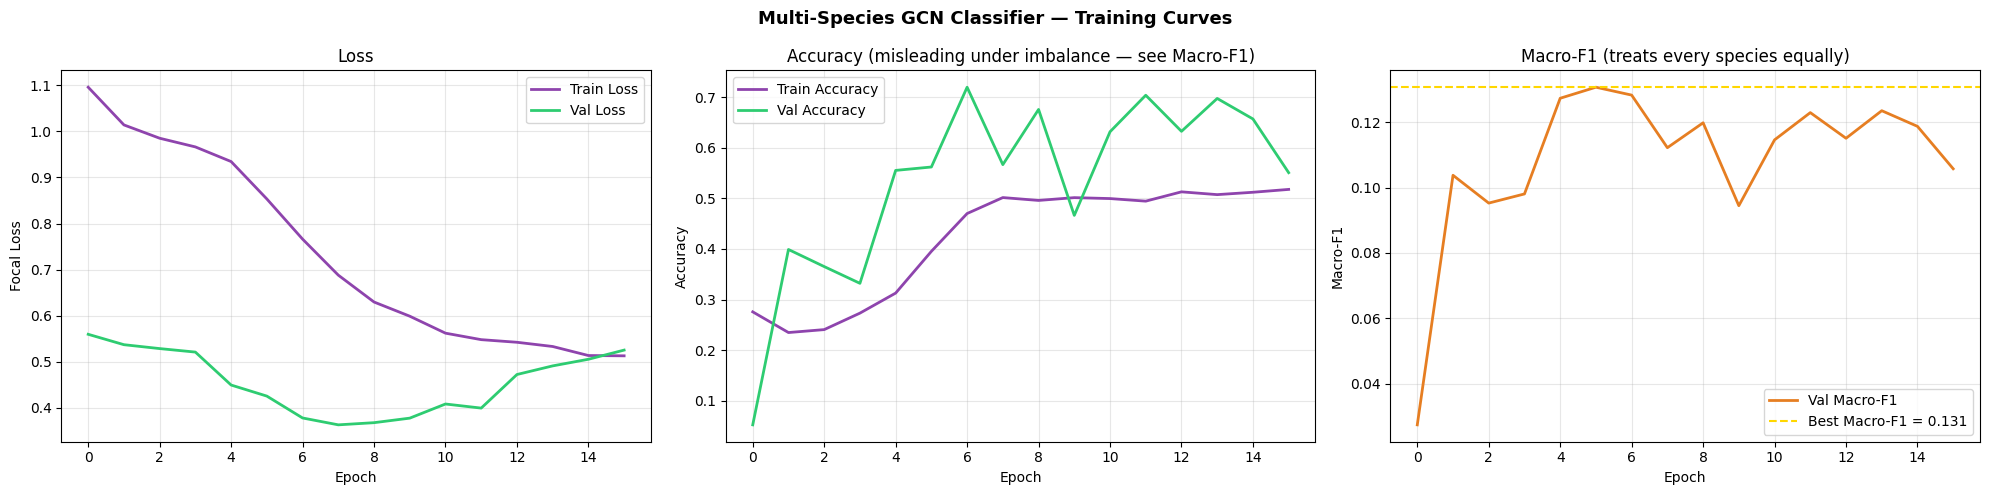

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].plot(train_losses, color='#8e44ad', label='Train Loss', linewidth=2)
axes[0].plot(val_losses,   color='#2ecc71', label='Val Loss',   linewidth=2)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Focal Loss')
axes[0].set_title('Loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(train_accs, color='#8e44ad', label='Train Accuracy', linewidth=2)
axes[1].plot(val_accs,   color='#2ecc71', label='Val Accuracy',   linewidth=2)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy (misleading under imbalance \u2014 see Macro-F1)')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(val_f1s, color='#e67e22', label='Val Macro-F1', linewidth=2)
axes[2].axhline(best_val_f1, color='gold', linestyle='--', label=f'Best Macro-F1 = {best_val_f1:.3f}')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Macro-F1')
axes[2].set_title('Macro-F1 (treats every species equally)')
axes[2].legend(); axes[2].grid(True, alpha=0.3)

fig.suptitle('Multi-Species GCN Classifier \u2014 Training Curves', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('species_gcn_classifier_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 🧪 STEP 10: Test-Set Evaluation — Confusion Matrix & Per-Species Report
**What I'm doing:** Loading the best checkpoint, running it on the held-out test set, and
reporting per-species precision/recall/F1 plus a confusion matrix so you can see exactly which
species get confused with each other.


TEST SET — Classification Report
              precision    recall  f1-score   support

     Class 0      0.308     0.069     0.113       347
    Elephant      0.909     0.608     0.728     10282
     Class 2      0.000     0.000     0.000        30
     Class 4      0.000     0.000     0.000        39
     Class 5      0.034     0.352     0.062       108
     Class 6      0.085     0.327     0.135       698
     Class 7      0.000     0.000     0.000         8
     Class 9      0.027     0.258     0.049        89

    accuracy                          0.565     11601
   macro avg      0.170     0.202     0.136     11601
weighted avg      0.821     0.565     0.658     11601



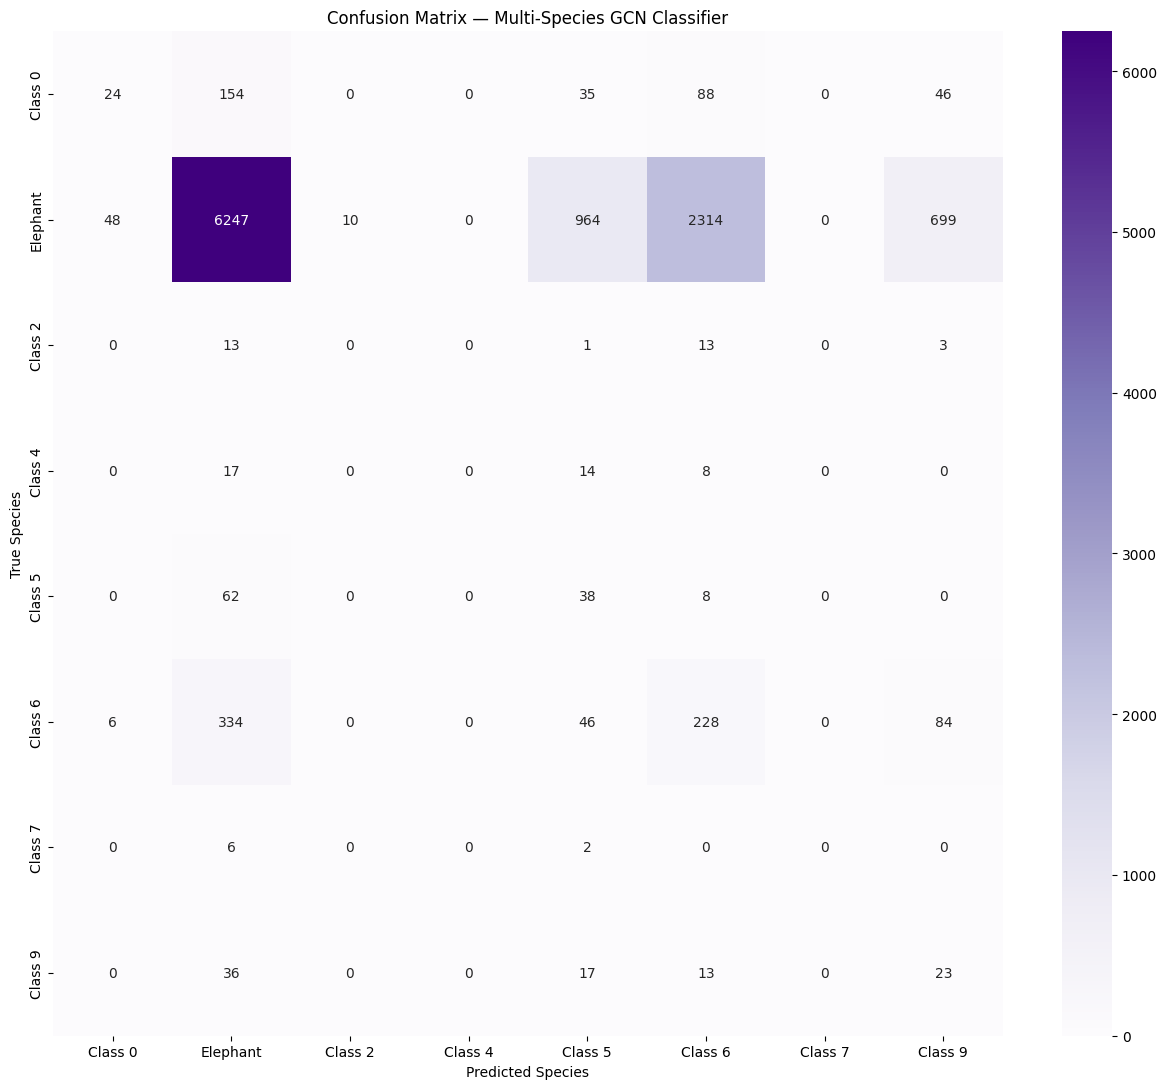

In [10]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

all_preds, all_true = [], []
with torch.no_grad():
    for data in test_loader:
        data = data.to(device)
        logits, _ = model(data.x, data.edge_index, data.batch)
        preds = logits.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(data.y.cpu().numpy())

target_names = [idx_to_name[i] for i in range(num_classes)]
print('=' * 70)
print('TEST SET — Classification Report')
print('=' * 70)
print(classification_report(
    all_true, all_preds,
    labels=list(range(num_classes)),
    target_names=target_names,
    digits=3,
    zero_division=0
))

cm = confusion_matrix(all_true, all_preds)
plt.figure(figsize=(1.2*num_classes + 3, 1.0*num_classes + 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted Species'); plt.ylabel('True Species')
plt.title('Confusion Matrix — Multi-Species GCN Classifier')
plt.tight_layout()
plt.savefig('species_gcn_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 🔮 STEP 11: Classify a New Incoming Signal
**What I'm doing:** This is the real "given a new signal, which species is it?" step. Pass any
raw `(3, 2048)` seismic signal (from a new field recording, not seen in training) into
`predict_species()` — it extracts the graph the same way as training, runs it through the
trained model, and returns the predicted species with a confidence score and the full
probability distribution across species.


In [11]:
@torch.no_grad()
def predict_species(signal_3d, model=model, top_k=3):
    """
    signal_3d : np.ndarray of shape (3, 2048) — raw X/Y/Z seismic signal
    Returns: predicted species name, confidence, and top-k probabilities.
    """
    g = extract_raw_peaks_graph(signal_3d, label=0,  # label unused at inference time
                                 prominence=PROMINENCE, distance=DISTANCE,
                                 k_neighbors=K_NEIGHBORS, window=WINDOW)
    if g is None:
        return {'error': 'Could not extract enough footstep peaks from this signal.'}

    model.eval()
    batch = torch.zeros(g.num_nodes, dtype=torch.long)  # single graph -> all nodes batch 0
    logits, _ = model(g.x.to(device), g.edge_index.to(device), batch.to(device))
    probs = F.softmax(logits, dim=1).cpu().numpy()[0]

    pred_idx = int(probs.argmax())
    top_k_idx = probs.argsort()[::-1][:top_k]

    return {
        'predicted_species': idx_to_name[pred_idx],
        'confidence': float(probs[pred_idx]),
        'top_k': [(idx_to_name[i], float(probs[i])) for i in top_k_idx],
    }

# ── Demo: classify a few held-out test signals ──────────────────────────────
demo_indices = test_idx[:5]
print('Demo predictions on unseen test signals:\n')
for i in demo_indices:
    true_species = idx_to_name[raw_to_new_idx[int(raw_labels[i])]]
    result = predict_species(selected_chunks[i])
    if 'error' in result:
        print(f'  Sample {i}: {result["error"]}')
        continue
    print(f'  Sample {i} | True: {true_species:15s} | '
          f'Predicted: {result["predicted_species"]:15s} | '
          f'Confidence: {result["confidence"]*100:.1f}%')
    print(f'      Top-{len(result["top_k"])}: ' +
          ', '.join(f'{name} ({p*100:.1f}%)' for name, p in result['top_k']))


Demo predictions on unseen test signals:

  Sample 54232 | True: Elephant        | Predicted: Class 5         | Confidence: 23.1%
      Top-3: Class 5 (23.1%), Elephant (21.7%), Class 6 (20.3%)
  Sample 6409 | True: Elephant        | Predicted: Class 6         | Confidence: 24.9%
      Top-3: Class 6 (24.9%), Class 9 (23.4%), Elephant (17.9%)
  Sample 52204 | True: Elephant        | Predicted: Elephant        | Confidence: 24.1%
      Top-3: Elephant (24.1%), Class 6 (23.0%), Class 5 (19.4%)
  Sample 53985 | True: Elephant        | Predicted: Class 5         | Confidence: 22.5%
      Top-3: Class 5 (22.5%), Elephant (20.9%), Class 6 (20.1%)
  Sample 6351 | True: Elephant        | Predicted: Elephant        | Confidence: 28.4%
      Top-3: Elephant (28.4%), Class 6 (25.4%), Class 5 (12.0%)


---
## 🧾 STEP 11b: Test the Model on Samples You Already Have
**What I'm doing:** You don't need brand-new field recordings to test this — any sample from
the dataset that the model didn't train on (the held-out **test split**) works as a fair test,
since the model never saw its features during training. This cell gives you two ways to test:

1. **Pick specific sample indices yourself** (from the full dataset) and see true vs. predicted.
2. **Run the full test set** through `predict_species()` one-by-one and get an overall accuracy
   + per-species breakdown, purely using the samples you already have.


In [12]:
# ── Option 1: Test specific samples by index ────────────────────────────────
# Put ANY indices here (0 .. len(selected_chunks)-1). Using test_idx keeps the test "fair"
# since those samples were held out of training -- but you can pass any index you like.
SAMPLE_INDICES_TO_TEST = list(test_idx[:10])   # <- edit this list freely

print('Testing selected samples:\n')
for i in SAMPLE_INDICES_TO_TEST:
    true_species = idx_to_name[raw_to_new_idx[int(raw_labels[i])]]
    result = predict_species(selected_chunks[i])
    if 'error' in result:
        print(f'  Sample {i}: {result["error"]}')
        continue
    match = '\u2705' if result['predicted_species'] == true_species else '\u274c'
    print(f'  {match} Sample {i:6d} | True: {true_species:15s} | '
          f'Predicted: {result["predicted_species"]:15s} | '
          f'Confidence: {result["confidence"]*100:.1f}%')


Testing selected samples:

  ❌ Sample  54232 | True: Elephant        | Predicted: Class 5         | Confidence: 23.1%
  ❌ Sample   6409 | True: Elephant        | Predicted: Class 6         | Confidence: 24.9%
  ✅ Sample  52204 | True: Elephant        | Predicted: Elephant        | Confidence: 24.1%
  ❌ Sample  53985 | True: Elephant        | Predicted: Class 5         | Confidence: 22.5%
  ✅ Sample   6351 | True: Elephant        | Predicted: Elephant        | Confidence: 28.4%
  ✅ Sample    943 | True: Elephant        | Predicted: Elephant        | Confidence: 27.2%
  ❌ Sample  54117 | True: Elephant        | Predicted: Class 5         | Confidence: 25.2%
  ✅ Sample  19492 | True: Elephant        | Predicted: Elephant        | Confidence: 26.8%
  ✅ Sample  56156 | True: Elephant        | Predicted: Elephant        | Confidence: 26.0%
  ✅ Sample  52885 | True: Elephant        | Predicted: Elephant        | Confidence: 26.8%


In [14]:
# ── Helper: run the model on an already-extracted graph (no re-extraction) ──
@torch.no_grad()
def predict_from_graph(g, model=model, top_k=3):
    model.eval()
    batch = torch.zeros(g.num_nodes, dtype=torch.long)
    logits, _ = model(g.x.to(device), g.edge_index.to(device), batch.to(device))
    probs = F.softmax(logits, dim=1).cpu().numpy()[0]
    pred_idx = int(probs.argmax())
    top_k_idx = probs.argsort()[::-1][:top_k]
    return {
        'predicted_species': idx_to_name[pred_idx],
        'confidence': float(probs[pred_idx]),
        'top_k': [(idx_to_name[i], float(probs[i])) for i in top_k_idx],
    }

# ── Demo: classify a few held-out test signals ──────────────────────────────
demo_indices = test_idx[:5]
print('Demo predictions on unseen test signals:\n')
for i in demo_indices:
    true_species = idx_to_name[graph_labels[i]]
    result = predict_from_graph(graph_dataset[i])
    print(f'  Sample {i} | True: {true_species:15s} | '
          f'Predicted: {result["predicted_species"]:15s} | '
          f'Confidence: {result["confidence"]*100:.1f}%')
    print(f'      Top-{len(result["top_k"])}: ' +
          ', '.join(f'{name} ({p*100:.1f}%)' for name, p in result['top_k']))

# ── Option 1: Test specific samples by index ────────────────────────────────
SAMPLE_INDICES_TO_TEST = list(test_idx[:10])   # indices into graph_dataset

print('\nTesting selected samples:\n')
for i in SAMPLE_INDICES_TO_TEST:
    true_species = idx_to_name[graph_labels[i]]
    result = predict_from_graph(graph_dataset[i])
    match = '✅' if result['predicted_species'] == true_species else '❌'
    print(f'  {match} Sample {i:6d} | True: {true_species:15s} | '
          f'Predicted: {result["predicted_species"]:15s} | '
          f'Confidence: {result["confidence"]*100:.1f}%')

# ── Option 2: Full test-set sweep ────────────────────────────────────────────
from collections import defaultdict

correct_per_class = defaultdict(int)
total_per_class = defaultdict(int)
overall_correct = 0

print(f'\nRunning predict_from_graph() on all {len(test_idx):,} held-out test samples...\n')
for i in tqdm(test_idx):
    true_species = idx_to_name[graph_labels[i]]
    result = predict_from_graph(graph_dataset[i])
    total_per_class[true_species] += 1
    if result['predicted_species'] == true_species:
        correct_per_class[true_species] += 1
        overall_correct += 1

print('=' * 60)
print(f'Overall accuracy on test split: '
      f'{overall_correct/len(test_idx)*100:.2f}%  ({overall_correct}/{len(test_idx)})')
print('=' * 60)
print('Per-species accuracy:')
for species in target_names:
    tot = total_per_class.get(species, 0)
    cor = correct_per_class.get(species, 0)
    if tot > 0:
        print(f'  {species:15s}: {cor}/{tot}  ({cor/tot*100:.1f}%)')
    else:
        print(f'  {species:15s}: no test samples')

Demo predictions on unseen test signals:

  Sample 54232 | True: Class 0         | Predicted: Elephant        | Confidence: 25.9%
      Top-3: Elephant (25.9%), Class 6 (25.2%), Class 5 (14.0%)
  Sample 6409 | True: Class 0         | Predicted: Elephant        | Confidence: 27.3%
      Top-3: Elephant (27.3%), Class 6 (26.7%), Class 5 (16.6%)
  Sample 52204 | True: Class 0         | Predicted: Elephant        | Confidence: 26.4%
      Top-3: Elephant (26.4%), Class 6 (25.4%), Class 5 (13.6%)
  Sample 53985 | True: Class 0         | Predicted: Elephant        | Confidence: 22.9%
      Top-3: Elephant (22.9%), Class 6 (22.1%), Class 0 (16.4%)
  Sample 6351 | True: Class 0         | Predicted: Class 6         | Confidence: 25.1%
      Top-3: Class 6 (25.1%), Elephant (24.7%), Class 5 (14.9%)

Testing selected samples:

  ❌ Sample  54232 | True: Class 0         | Predicted: Elephant        | Confidence: 25.9%
  ❌ Sample   6409 | True: Class 0         | Predicted: Elephant        | Confiden

100%|██████████| 11601/11601 [00:22<00:00, 504.90it/s]

Overall accuracy on test split: 56.55%  (6560/11601)
Per-species accuracy:
  Class 0        : 24/347  (6.9%)
  Elephant       : 6247/10282  (60.8%)
  Class 2        : 0/30  (0.0%)
  Class 4        : 0/39  (0.0%)
  Class 5        : 38/108  (35.2%)
  Class 6        : 228/698  (32.7%)
  Class 7        : 0/8  (0.0%)
  Class 9        : 23/89  (25.8%)
